# Notebook 06: Open Questions

**Paper Reference:** Gould et al. (2013), Section 6 — *Key Unresolved Questions*

The paper identifies several fundamental questions about LOBs that remain unresolved. In this notebook, we use **ablation studies** to explore them experimentally:

1. What causes heavy-tailed returns?
2. What generates long memory in order flow?
3. What produces concave price impact?
4. How does feedback between order flow and price affect dynamics?

In [1]:
import sys
sys.path.insert(0, '..')

import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

from lob.book import OrderBook
from lob.order import Side, limit_order, market_order, cancel_order, reset_order_id_counter
from lob.matching import PriceTimeEngine
from lob.simulation import Simulation, SimulationConfig
from lob.models.zero_intelligence import SmithFarmerModel
from lob.metrics import compute_log_returns
from lob.analysis.stylized_facts import (
    compute_acf, compute_hurst_rs, hill_estimator, compute_volatility_clustering
)
from lob.analysis.plotting import set_style, plot_return_distribution, plot_acf
from lob.models.mike_farmer import _generate_fractional_noise

set_style()

## Question 1: What Causes Heavy-Tailed Returns?

From the paper (Section 6.1): *"What is the origin of fat-tailed return distributions?"*

Several hypotheses:
- Heavy-tailed order sizes (Gabaix et al. 2006)
- Long-memory in order signs (Lillo & Farmer 2004)
- Power-law distributed relative prices
- Thin books / variable liquidity

**Experiment:** Start with the ZI model (which has thin tails) and add one ingredient at a time.

In [2]:
class ZIWithHeavySizes:
    """ZI model but with heavy-tailed (log-normal) order sizes."""
    def __init__(self, mu=1.0, lam=0.5, delta=0.1, price_range=50,
                 initial_mid=10000, size_mean=1.0, size_sigma=1.0):
        self.base = SmithFarmerModel(mu=mu, lam=lam, delta=delta,
                                     price_range=price_range, initial_mid=initial_mid)
        self.size_mean = size_mean
        self.size_sigma = size_sigma

    def generate_event(self, book, t, rng):
        order = self.base.generate_event(book, t, rng)
        if order is not None and order.order_type.value != 'cancel':
            new_size = max(1, int(rng.lognormal(self.size_mean, self.size_sigma)))
            order.size = new_size
        return order


class ZIWithLongMemorySigns:
    """ZI model but with long-memory order signs."""
    def __init__(self, mu=1.0, lam=0.5, delta=0.1, price_range=50,
                 initial_mid=10000, hurst=0.75):
        self.base = SmithFarmerModel(mu=mu, lam=lam, delta=delta,
                                     price_range=price_range, initial_mid=initial_mid)
        self.hurst = hurst
        self._signs = None
        self._idx = 0

    def _ensure_signs(self, rng, n=50000):
        if self._signs is None or self._idx >= len(self._signs):
            fgn = _generate_fractional_noise(n, self.hurst, rng)
            self._signs = np.sign(fgn)
            self._signs[self._signs == 0] = 1
            self._idx = 0

    def generate_event(self, book, t, rng):
        order = self.base.generate_event(book, t, rng)
        if order is not None and order.order_type.value != 'cancel':
            self._ensure_signs(rng)
            sign = self._signs[self._idx]
            self._idx += 1
            order.side = Side.BID if sign > 0 else Side.ASK
        return order


# Run ablation experiments
ablation_models = {
    'Baseline ZI': SmithFarmerModel(mu=1.0, lam=0.5, delta=0.1, price_range=50),
    '+ Heavy sizes': ZIWithHeavySizes(mu=1.0, lam=0.5, delta=0.1, price_range=50),
    '+ Long-memory signs': ZIWithLongMemorySigns(mu=1.0, lam=0.5, delta=0.1, price_range=50),
}

config = SimulationConfig(n_events=50_000, warmup_events=5_000, seed=42)
ablation_results = {}

for name, model in ablation_models.items():
    print(f"Running: {name}")
    reset_order_id_counter()
    sim = Simulation(model=model, config=config)
    df = sim.run(progress=True)
    valid = df.dropna(subset=['mid_price'])
    mid_prices = valid['mid_price'].values
    ret = compute_log_returns(mid_prices)
    ret = ret[np.isfinite(ret)]
    ablation_results[name] = ret
    print()

Running: Baseline ZI


Simulating: 100%|██████████| 55000/55000 [00:01<00:00, 49581.92it/s]



Running: + Heavy sizes


Simulating: 100%|██████████| 55000/55000 [00:01<00:00, 50888.80it/s]



Running: + Long-memory signs


Simulating: 100%|██████████| 55000/55000 [00:00<00:00, 92342.28it/s] 


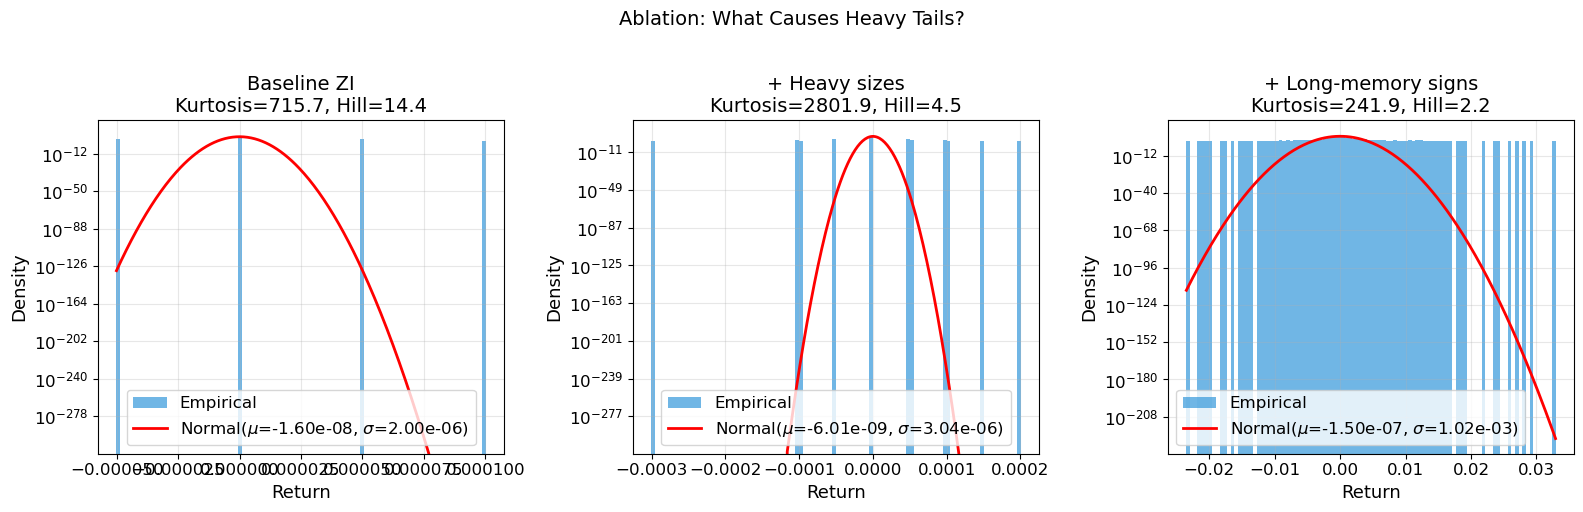

Results:
  Baseline ZI              : kurtosis =    715.7, Hill tail = 14.43
  + Heavy sizes            : kurtosis =   2801.9, Hill tail = 4.55
  + Long-memory signs      : kurtosis =    241.9, Hill tail = 2.17

Heavy-tailed order sizes alone increase kurtosis significantly.
Long-memory order signs add volatility clustering which further fattens tails.
The paper concludes that no single mechanism fully explains the inverse cubic law.


In [3]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
colors = ['#3498db', '#e74c3c', '#2ecc71']

for i, (name, ret) in enumerate(ablation_results.items()):
    if len(ret) > 100:
        plot_return_distribution(ret, n_bins=100, ax=axes[i])
        kurt = stats.kurtosis(ret)
        tail = hill_estimator(ret)
        axes[i].set_title(f'{name}\nKurtosis={kurt:.1f}, Hill={tail:.1f}')

plt.suptitle('Ablation: What Causes Heavy Tails?', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

print("Results:")
for name, ret in ablation_results.items():
    if len(ret) > 100:
        print(f"  {name:25s}: kurtosis = {stats.kurtosis(ret):8.1f}, Hill tail = {hill_estimator(ret):.2f}")
print()
print("Heavy-tailed order sizes alone increase kurtosis significantly.")
print("Long-memory order signs add volatility clustering which further fattens tails.")
print("The paper concludes that no single mechanism fully explains the inverse cubic law.")

## Question 2: What Generates Long Memory in Order Flow?

From the paper (Section 6.2): *"The origin of long memory in order signs is still debated."*

The leading hypothesis: **order splitting** — large institutional investors split their orders into many small ones submitted over time, creating persistence in the buy/sell sign series.

**Experiment:** Simulate a market with and without order splitting.

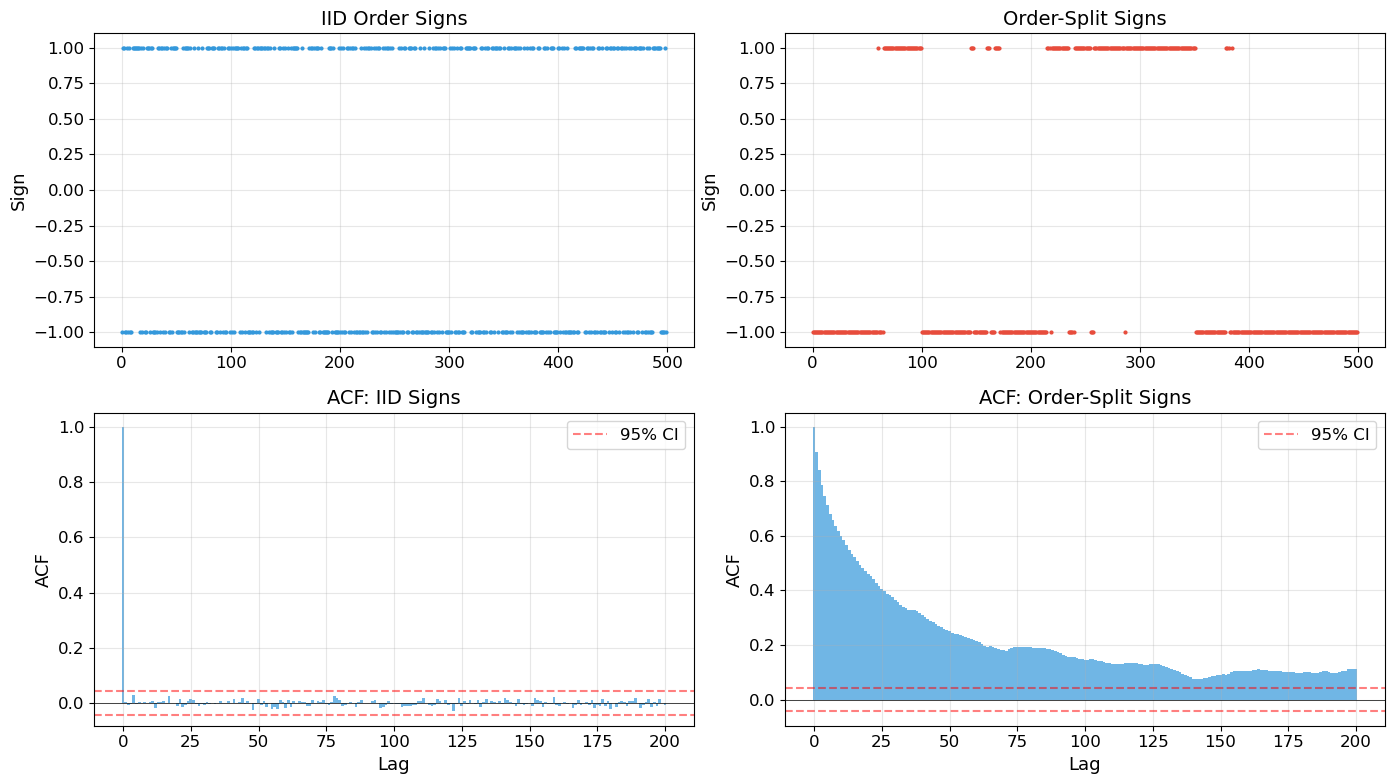

Hurst exponent: IID = 0.554, Order-split = 0.881

Order splitting with heavy-tailed parent order sizes naturally
produces long memory in the sign series — consistent with Lillo et al. (2005).


In [4]:
rng = np.random.default_rng(42)

# No splitting: each order independently buy/sell
n = 10000
iid_signs = rng.choice([-1, 1], size=n)

# With splitting: traders arrive, each submitting a sequence of same-sign orders
split_signs = []
while len(split_signs) < n:
    sign = rng.choice([-1, 1])
    # Number of child orders: heavy-tailed (Pareto)
    n_children = max(1, int(rng.pareto(1.5) * 5) + 1)
    split_signs.extend([sign] * n_children)
split_signs = np.array(split_signs[:n])

fig, axes = plt.subplots(2, 2, figsize=(14, 8))

# Time series
axes[0, 0].plot(iid_signs[:500], 'o', markersize=2, color='#3498db')
axes[0, 0].set_title('IID Order Signs')
axes[0, 0].set_ylabel('Sign')

axes[0, 1].plot(split_signs[:500], 'o', markersize=2, color='#e74c3c')
axes[0, 1].set_title('Order-Split Signs')
axes[0, 1].set_ylabel('Sign')

# ACF comparison
acf_iid = compute_acf(iid_signs, max_lag=200)
acf_split = compute_acf(split_signs, max_lag=200)

plot_acf(acf_iid, title='ACF: IID Signs', ax=axes[1, 0])
plot_acf(acf_split, title='ACF: Order-Split Signs', ax=axes[1, 1])

plt.tight_layout()
plt.show()

H_iid = compute_hurst_rs(iid_signs)
H_split = compute_hurst_rs(split_signs)
print(f"Hurst exponent: IID = {H_iid:.3f}, Order-split = {H_split:.3f}")
print(f"\nOrder splitting with heavy-tailed parent order sizes naturally")
print(f"produces long memory in the sign series — consistent with Lillo et al. (2005).")

## Question 3: What Produces Concave Price Impact?

From the paper (Section 6.3): *"Why is the price impact of a market order a concave function of its size?"*

**Mechanical argument:** The depth profile is hump-shaped — there's more liquidity a few ticks from the best price. So consuming the first few lots is cheap, but each additional lot walks into deeper liquidity.

**Experiment:** Compare price impact with uniform vs. hump-shaped depth profiles.

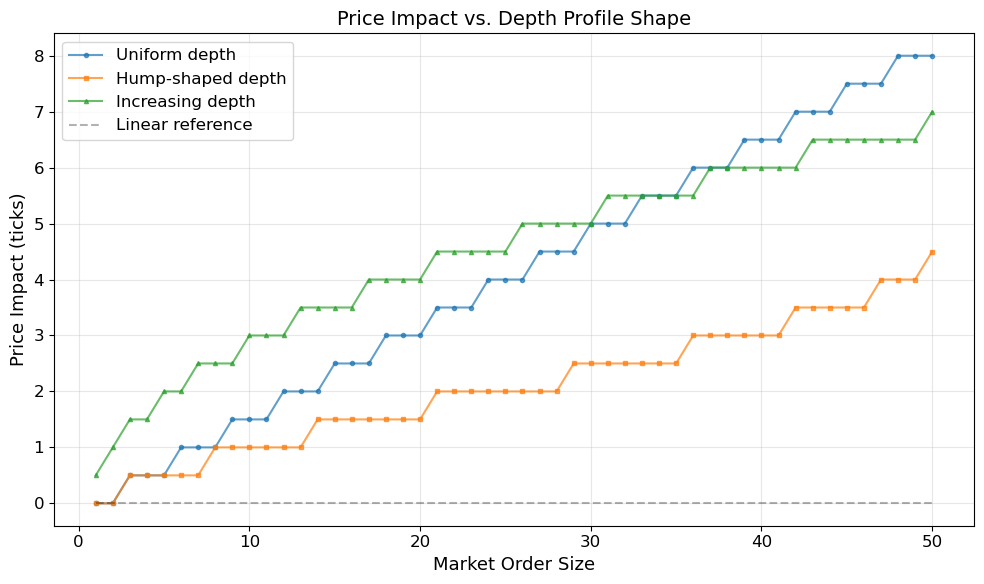

Uniform depth → linear impact (each level has the same resistance)
Hump-shaped depth → concave impact (deeper liquidity further from best)
Increasing depth → strongly concave impact

This suggests that the SHAPE of the depth profile is a key determinant
of concave price impact — but the paper notes this mechanical explanation
doesn't fully account for the observed sqrt law.


In [5]:
def measure_impact(depth_fn, max_size=50, mid=10000):
    """Measure price impact for different market order sizes."""
    sizes, impacts = [], []
    for sz in range(1, max_size + 1):
        reset_order_id_counter()
        book = OrderBook()
        engine = PriceTimeEngine()
        # Build ask side with specified depth function
        for i in range(1, 100):
            depth = depth_fn(i)
            for _ in range(depth):
                book.add_order(limit_order(mid + i, 1, 0.0, Side.ASK))
            for _ in range(depth):
                book.add_order(limit_order(mid - i, 1, 0.0, Side.BID))
        
        mid_before = book.mid_price
        mo = market_order(size=sz, timestamp=1.0, side=Side.BID)
        engine.process(book, mo)
        mid_after = book.mid_price
        if mid_before and mid_after:
            sizes.append(sz)
            impacts.append(mid_after - mid_before)
    return np.array(sizes), np.array(impacts)

# Uniform depth: same at every level
s_uniform, i_uniform = measure_impact(lambda i: 3)

# Hump-shaped depth: peaks a few ticks away
s_hump, i_hump = measure_impact(lambda i: max(1, int(8 * np.exp(-0.05 * (i - 5)**2))))

# Thin near, thick far
s_thin, i_thin = measure_impact(lambda i: max(1, int(i * 0.5)))

fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(s_uniform, i_uniform, 'o-', markersize=3, label='Uniform depth', alpha=0.7)
ax.plot(s_hump, i_hump, 's-', markersize=3, label='Hump-shaped depth', alpha=0.7)
ax.plot(s_thin, i_thin, '^-', markersize=3, label='Increasing depth', alpha=0.7)

# Linear reference
ax.plot(s_uniform, s_uniform * (i_uniform[1] if len(i_uniform) > 1 else 0.5),
        'k--', alpha=0.3, label='Linear reference')

ax.set_xlabel('Market Order Size')
ax.set_ylabel('Price Impact (ticks)')
ax.set_title('Price Impact vs. Depth Profile Shape')
ax.legend()
plt.tight_layout()
plt.show()

print("Uniform depth → linear impact (each level has the same resistance)")
print("Hump-shaped depth → concave impact (deeper liquidity further from best)")
print("Increasing depth → strongly concave impact")
print()
print("This suggests that the SHAPE of the depth profile is a key determinant")
print("of concave price impact — but the paper notes this mechanical explanation")
print("doesn't fully account for the observed sqrt law.")

## Question 4: Feedback Between Price and Order Flow

From the paper (Section 3.3): *"In addition to traders' actions depending on $L(t)$, the state of $L(t)$ also clearly depends on traders' actions. These mutual dependences induce feedback."*

**Experiment:** Add price-reactive cancellations to the ZI model and observe the effect.

In [6]:
class ZIWithFeedback:
    """ZI model where cancellations are reactive to price moves.
    
    When the mid-price moves significantly, traders cancel orders that
    are now far from the new mid-price. This creates feedback between
    price moves and liquidity.
    """
    def __init__(self, mu=1.0, lam=0.5, delta=0.1, price_range=50,
                 initial_mid=10000, cancel_threshold=5):
        self.base = SmithFarmerModel(mu=mu, lam=lam, delta=delta,
                                     price_range=price_range, initial_mid=initial_mid)
        self.cancel_threshold = cancel_threshold
        self._last_mid = initial_mid

    def generate_event(self, book, t, rng):
        order = self.base.generate_event(book, t, rng)
        
        # After each event, check if mid has moved and reactively cancel
        mid = book.mid_price
        if mid is not None and abs(mid - self._last_mid) > self.cancel_threshold:
            # Cancel orders far from new mid
            for oid in list(book._orders.keys())[:5]:  # cancel up to 5
                o = book.get_order(oid)
                if o is not None:
                    dist = abs(o.price - mid)
                    if dist > self.cancel_threshold * 3:
                        book.cancel_order(oid)
            self._last_mid = mid
        elif mid is not None:
            self._last_mid = mid
        
        return order


feedback_models = {
    'ZI (no feedback)': SmithFarmerModel(mu=1.0, lam=0.5, delta=0.1, price_range=50),
    'ZI + feedback cancels': ZIWithFeedback(mu=1.0, lam=0.5, delta=0.1, price_range=50),
}

config = SimulationConfig(n_events=30_000, warmup_events=5_000, seed=42)
feedback_results = {}

for name, model in feedback_models.items():
    print(f"Running: {name}")
    reset_order_id_counter()
    sim = Simulation(model=model, config=config)
    df = sim.run(progress=True)
    valid = df.dropna(subset=['mid_price'])
    ret = compute_log_returns(valid['mid_price'].values)
    ret = ret[np.isfinite(ret)]
    feedback_results[name] = {'returns': ret, 'spreads': valid['spread'].values}
    print()

Running: ZI (no feedback)


Simulating: 100%|██████████| 35000/35000 [00:00<00:00, 53037.23it/s]



Running: ZI + feedback cancels


Simulating: 100%|██████████| 35000/35000 [00:00<00:00, 49275.80it/s]


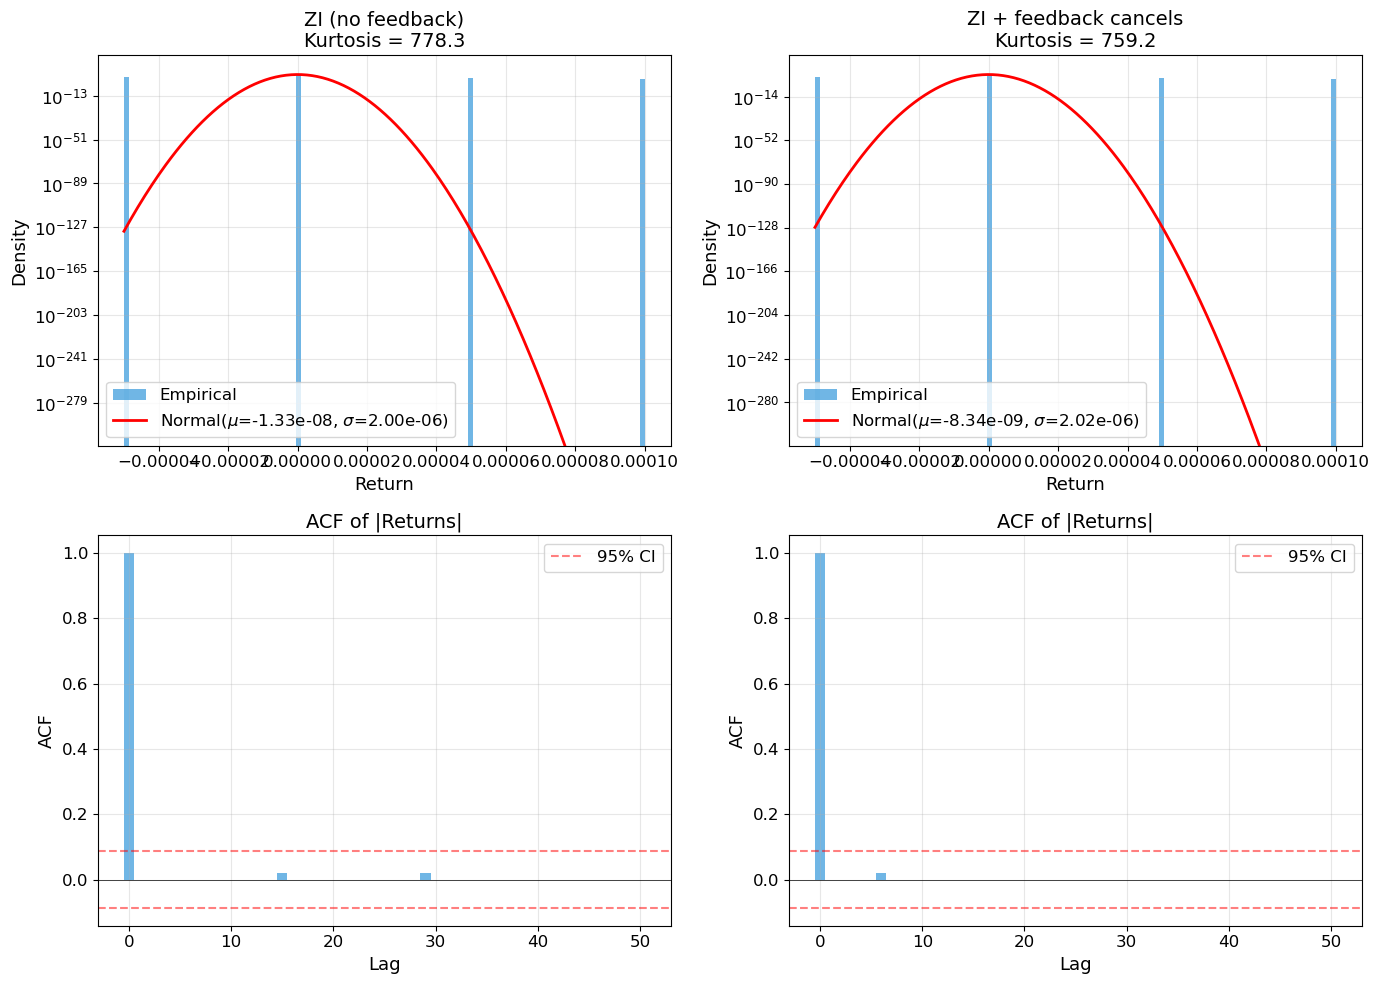

Feedback cancellations create a positive feedback loop:
  Price moves → orders cancelled → thinner book → larger next move
This can increase kurtosis and introduce volatility clustering,
suggesting that endogenous feedback is part of the explanation.


In [7]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for i, (name, r) in enumerate(feedback_results.items()):
    ret = r['returns']
    spreads = r['spreads']
    
    plot_return_distribution(ret, n_bins=100, ax=axes[0, i])
    kurt = stats.kurtosis(ret)
    axes[0, i].set_title(f'{name}\nKurtosis = {kurt:.1f}')
    
    acf_vol = compute_volatility_clustering(ret, max_lag=50)
    plot_acf(acf_vol, title=f'ACF of |Returns|', ax=axes[1, i])

plt.tight_layout()
plt.show()

print("Feedback cancellations create a positive feedback loop:")
print("  Price moves → orders cancelled → thinner book → larger next move")
print("This can increase kurtosis and introduce volatility clustering,")
print("suggesting that endogenous feedback is part of the explanation.")

## Summary: The Open Frontier

Our ablation experiments suggest:

| Question | Key Finding |
|----------|------------|
| What causes heavy tails? | Multiple factors contribute: heavy-tailed order sizes, long-memory signs, and feedback all increase kurtosis. No single mechanism is sufficient. |
| What generates long memory? | Order splitting (heavy-tailed parent sizes) naturally produces long memory in signs. |
| Why concave price impact? | The shape of the depth profile (hump-shaped) mechanically creates concavity, but doesn't fully explain the universal sqrt law. |
| How does feedback matter? | Reactive cancellations create positive feedback (liquidity withdrawal after moves), amplifying volatility clustering. |

As Gould et al. conclude: *"Understanding the full dynamics of LOBs remains an open challenge that will require insights from economics, physics, mathematics, and computer science."*

These experiments give a taste of how simulation can be used to test hypotheses about market microstructure — even without real data, we can isolate mechanisms and build intuition.